In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafiklerin şık ve temiz görünmesi için stil ayarı
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Library is ready!")


Library is ready!


In [3]:
train_df = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print("--- data information ---")
train_df.info()

print("\n--- missing values ---")
print(train_df.isnull().sum())

--- data information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

--- missing values ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin

In this data we should have 891 entries each colm but we can see very serious 'age'and'cabin' values was missed.So we can not receive very absolute results but maybe especially in age colmn we can generalizate something but cabin colm are too big therefore we can't take this colm mainly and also we have 2 missing 'embarked' values but its few so we can ignore this values.

/tmp/ipykernel_16/3351624631.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=train_df, x='Survived', palette=['#d9534f', '#5cb85c'])


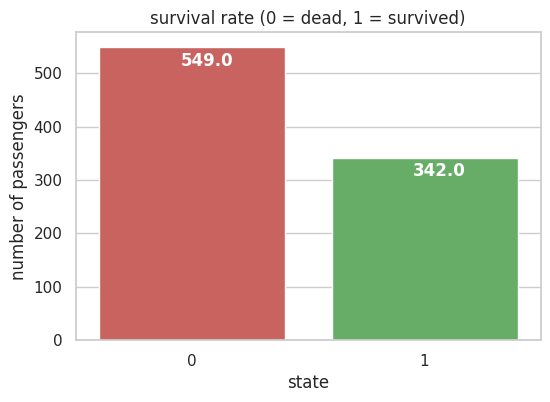

In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=train_df, x='Survived', palette=['#d9534f', '#5cb85c'])
plt.title('survival rate (0 = dead, 1 = survived)')
plt.xlabel('state')
plt.ylabel('number of passengers')

# Çubukların üzerine sayıları yazdıralım
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + 0.35, p.get_height() - 35), color='white', fontweight='bold')

plt.show()

In this graph we have numbers of passangers and their current (after accident) state datas.We can say many passangers are dead and low percent of them are survived this results shows that this is more than simple accident it is actually disaster

/tmp/ipykernel_16/3311470289.py:8: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=train_df, x='Sex', y='Survived', palette='Blues_d', ci=None, ax=axes[1])
/tmp/ipykernel_16/3311470289.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_df, x='Sex', y='Survived', palette='Blues_d', ci=None, ax=axes[1])


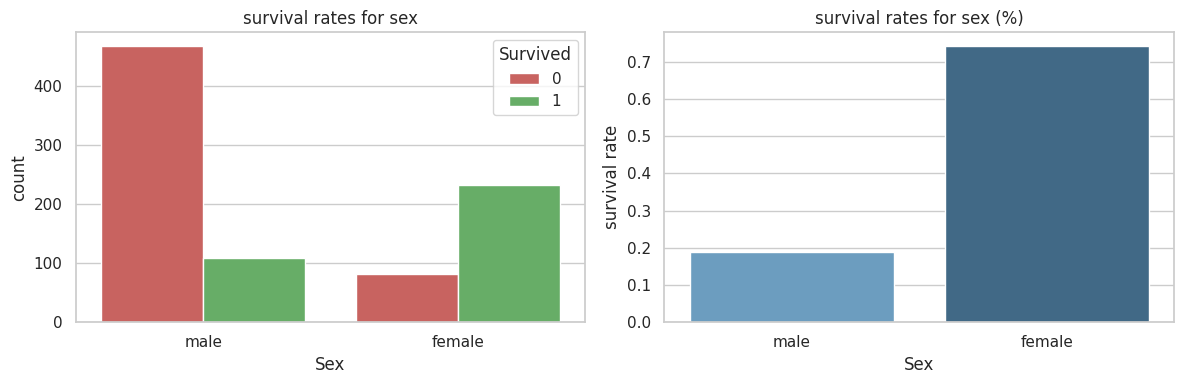

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Sayısal dağılım
sns.countplot(data=train_df, x='Sex', hue='Survived', palette=['#d9534f', '#5cb85c'], ax=axes[0])
axes[0].set_title('survival rates for sex')

# Yüzdelik oran
sns.barplot(data=train_df, x='Sex', y='Survived', palette='Blues_d', ci=None, ax=axes[1])
axes[1].set_title('survival rates for sex (%)')
axes[1].set_ylabel('survival rate')

plt.tight_layout()
plt.show()

the visualization shows that number of survived female passenger more than number of survived male passenger its hard to say but I guess that male passengers give their lifeboat to their wife or children and maybe male passangers thought they can rescue from this disaster

/tmp/ipykernel_16/4238351604.py:10: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=train_df, x='Pclass', y='Survived', palette='Blues_d', ci=None, ax=axes[1])
/tmp/ipykernel_16/4238351604.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_df, x='Pclass', y='Survived', palette='Blues_d', ci=None, ax=axes[1])


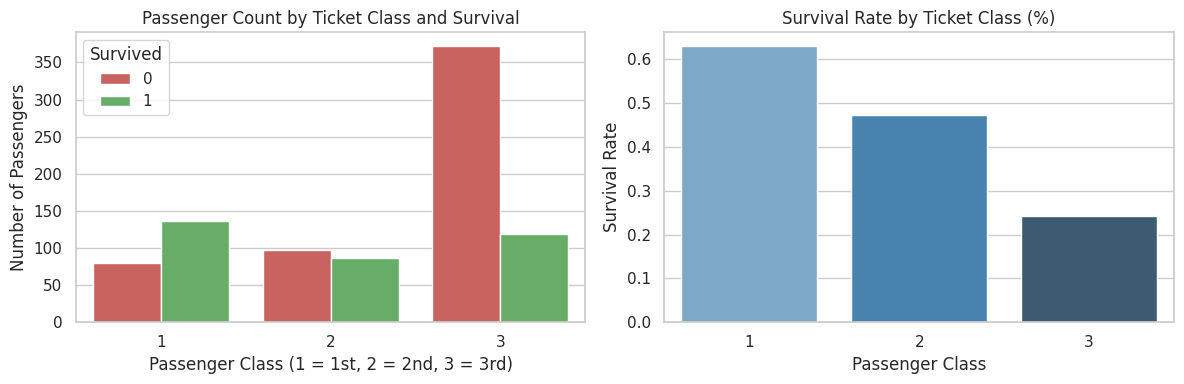

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bilet sınıfına göre yolcu ve hayatta kalma sayısı
sns.countplot(data=train_df, x='Pclass', hue='Survived', palette=['#d9534f', '#5cb85c'], ax=axes[0])
axes[0].set_title('Passenger Count by Ticket Class and Survival')
axes[0].set_xlabel('Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)')
axes[0].set_ylabel('Number of Passengers')

# Bilet sınıfına göre kurtulma oranı (%)
sns.barplot(data=train_df, x='Pclass', y='Survived', palette='Blues_d', ci=None, ax=axes[1])
axes[1].set_title('Survival Rate by Ticket Class (%)')
axes[1].set_xlabel('Passenger Class')
axes[1].set_ylabel('Survival Rate')

plt.tight_layout()
plt.show()

In these graph we can see number of passengers distribution to passanger class and survival rate by ticket class fraction 
Third class: we can say the most people in third class and roughly %75 of them was dead.

second class: In second class survived and dead fractions are same and number of passengers likewise first class and lowest number of survived passangers in this class 

first class :In first class mean that luxury one more people was survived

Maybe we can interpret this results first class tickets provide more close to lifeboat and they can escape faster than other groups so third class passangers further to lifeboats and maybe they stuck in wrong side of ship

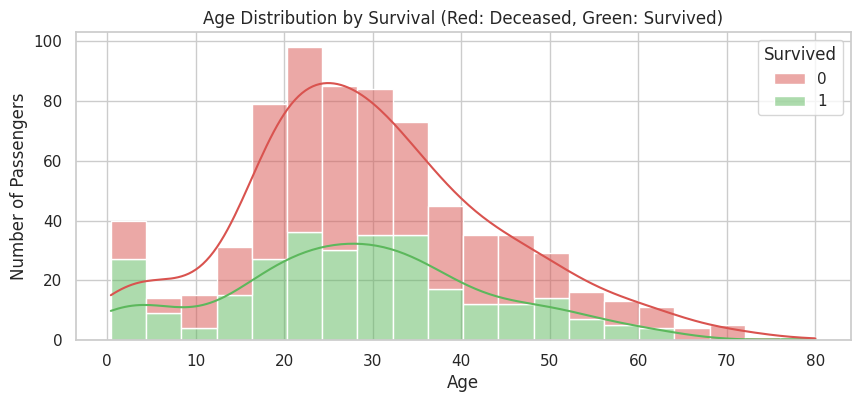

In [8]:
plt.figure(figsize=(10, 4))
sns.histplot(data=train_df, x='Age', hue='Survived', multiple='stack', kde=True, palette=['#d9534f', '#5cb85c'])
plt.title('Age Distribution by Survival (Red: Deceased, Green: Survived)')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()

this graph shows that every age band gave some lost but especially in young ages 0-10 childs could rescue more than olders as I said in previous analysis parents (i guess fathers) put their childs in lifeboat and older ones cant get in lifeboat and cant swim cold ocean